# Experiments 9–10: a fourth convolution layer

Both variants start independently from the current 05 candidate: three convolution/pooling blocks, a 64-unit classifier, dropout 0.5 and AdamW weight decay 1e-4.

- **Experiment 9:** add `Conv2d(64, 64, 3, padding=1)` and ReLU after the third block; no extra pooling. The feature map remains 64 × 9 × 9 and the classifier stays the same.
- **Experiment 10:** add `Conv2d(64, 128, 3, padding=1)`, ReLU and `MaxPool2d(2)` after the third block. The feature map becomes 128 × 4 × 4; the classifier input changes to 2,048 values.

Both are image-only. Each uses the same augmentation, AdamW learning rate 0.001, batch size 32, up to 40 epochs, patience 6, training seed 42 and stratified five-fold splits with shuffle and split seeds 42, 123 and 2024 as the candidate. Image normalization is fitted only on each training fold. The reference scores below are copied from the actual 05 runs; seed 42 was previously used to select the candidate and its saved fold numbers have six decimal places.

Each validation fold selects the best epoch and contributes to comparison; selection and overlapping training folds limit the interpretation. One training seed per fold cannot characterize random initialization and augmentation variability. Use nested CV or an untouched test set and repeat training seeds before claiming final generalization. Different architectures can consume random numbers differently even with identical seeds.


In [1]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import Dataset, DataLoader, TensorDataset

train = pd.read_json("data/train.json")
band1 = np.stack(train["band_1"]).reshape(-1, 75, 75)
band2 = np.stack(train["band_2"]).reshape(-1, 75, 75)
X = np.stack([band1, band2], axis=1).astype(np.float32)
y = train["is_iceberg"].to_numpy(dtype=np.int64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Images:", X.shape, "| labels:", y.shape, "| device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Images: (1604, 2, 75, 75) | labels: (1604,) | device: cuda
GPU: NVIDIA GeForce RTX 4090 Laptop GPU


In [2]:
class AugmentedImages(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images).float()
        self.labels = torch.from_numpy(labels).long()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index].clone()
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[2])
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=[1])
        return image, self.labels[index]


class FourthConvCNN(nn.Module):
    def __init__(self, experiment):
        super().__init__()
        if experiment not in (9, 10):
            raise ValueError("Choose experiment 9 or 10")
        # The first three blocks are the architecture from 05.
        layers = [
            nn.Conv2d(2, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        ]
        if experiment == 9:
            layers += [nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()]
            classifier_input = 64 * 9 * 9
        else:
            layers += [nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
            classifier_input = 128 * 4 * 4
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(classifier_input, 64),
                                        nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 2))

    def forward(self, images):
        return self.classifier(self.features(images))


# Shape and parameter checks, with no training.
for experiment in (9, 10):
    m = FourthConvCNN(experiment).eval()
    with torch.no_grad():
        features = m.features(torch.zeros(1, 2, 75, 75))
        output = m(torch.zeros(1, 2, 75, 75))
    expected = (1, 64, 9, 9) if experiment == 9 else (1, 128, 4, 4)
    assert tuple(features.shape) == expected and tuple(output.shape) == (1, 2)
    print(f"Experiment {experiment}: feature shape {tuple(features.shape)}, "
          f"parameters {sum(p.numel() for p in m.parameters()):,}")


Experiment 9: feature shape (1, 64, 9, 9), parameters 392,338
Experiment 10: feature shape (1, 128, 4, 4), parameters 228,562


In [ ]:
def evaluate_fold(experiment, train_idx, val_idx):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    X_tr, X_va = X[train_idx].copy(), X[val_idx].copy()
    y_tr, y_va = y[train_idx], y[val_idx]
    mean = X_tr.mean(axis=(0, 2, 3), keepdims=True)
    std = X_tr.std(axis=(0, 2, 3), keepdims=True)
    X_tr = (X_tr - mean) / (std + 1e-8)
    X_va = (X_va - mean) / (std + 1e-8)
    training = AugmentedImages(X_tr, y_tr)
    validation = TensorDataset(torch.from_numpy(X_va), torch.from_numpy(y_va))
    train_loader = DataLoader(training, batch_size=32, shuffle=True)
    val_loader = DataLoader(validation, batch_size=32, shuffle=False)
    model = FourthConvCNN(experiment).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0
    train_losses, val_losses = [], []
    for epoch in range(40):
        model.train()
        train_loss_sum = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)
        train_losses.append(train_loss_sum / len(training))
        model.eval()
        val_loss_sum = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                val_loss_sum += criterion(model(images), labels).item() * len(labels)
        val_loss = val_loss_sum / len(validation)
        val_losses.append(val_loss)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        if wait >= 6:
            break
    model.load_state_dict(best_state)
    model.eval()
    probs = []
    with torch.no_grad():
        for images, _ in val_loader:
            probs.extend(torch.softmax(model(images.to(device)), dim=1)[:, 1].cpu().numpy())
    probs = np.asarray(probs)
    return {"best_epoch": best_epoch, "log_loss": log_loss(y_va, probs, labels=[0, 1]),
            "accuracy": float(np.mean((probs >= 0.5) == y_va)),
            "parameters": sum(p.numel() for p in model.parameters()),
            "train_losses": train_losses, "val_losses": val_losses}


def run_experiment(experiment):
    histories = {}
    rows = []
    for seed in (42, 123, 2024):
        splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        for fold, (tr, va) in enumerate(splitter.split(X, y), 1):
            assert not np.intersect1d(tr, va).size
            result = evaluate_fold(experiment, tr, va)
            histories[(seed, fold)] = result
            rows.append({"experiment": experiment, "split_seed": seed, "fold": fold,
                         "best_epoch": result["best_epoch"], "log_loss": result["log_loss"],
                         "accuracy": result["accuracy"], "parameters": result["parameters"]})
            print(f"Experiment {experiment} | seed {seed} | fold {fold}: "
                  f"epoch {result['best_epoch']}, log loss {result['log_loss']:.6f}, "
                  f"accuracy {result['accuracy']:.4%}", flush=True)
    frame = pd.DataFrame(rows)
    print(frame.groupby("split_seed").agg(mean_log_loss=("log_loss", "mean"),
          std_fold_log_loss=("log_loss", "std"), mean_accuracy=("accuracy", "mean"),
          parameters=("parameters", "first")).to_string())
    return frame, histories


## 05 reference results

The fold-level reference is an immutable snapshot of the saved 05 runs.


In [ ]:
# Measured fold results from 05; seed 42 was saved at six-decimal precision.
reference_rows = [{'split_seed': 42, 'fold': 1, 'best_epoch': 23, 'log_loss': 0.243717, 'accuracy': 0.915888}, {'split_seed': 42, 'fold': 2, 'best_epoch': 32, 'log_loss': 0.222183, 'accuracy': 0.915888}, {'split_seed': 42, 'fold': 3, 'best_epoch': 17, 'log_loss': 0.297617, 'accuracy': 0.872274}, {'split_seed': 42, 'fold': 4, 'best_epoch': 24, 'log_loss': 0.188324, 'accuracy': 0.912773}, {'split_seed': 42, 'fold': 5, 'best_epoch': 14, 'log_loss': 0.276179, 'accuracy': 0.88125}, {'split_seed': 123, 'fold': 1, 'best_epoch': 17, 'log_loss': 0.26727133989334106, 'accuracy': 0.897196261682243}, {'split_seed': 123, 'fold': 2, 'best_epoch': 28, 'log_loss': 0.2525767385959625, 'accuracy': 0.8909657320872274}, {'split_seed': 123, 'fold': 3, 'best_epoch': 31, 'log_loss': 0.2825908660888672, 'accuracy': 0.8722741433021807}, {'split_seed': 123, 'fold': 4, 'best_epoch': 18, 'log_loss': 0.2567932903766632, 'accuracy': 0.8940809968847352}, {'split_seed': 123, 'fold': 5, 'best_epoch': 23, 'log_loss': 0.20381192862987518, 'accuracy': 0.909375}, {'split_seed': 2024, 'fold': 1, 'best_epoch': 24, 'log_loss': 0.2144031524658203, 'accuracy': 0.9190031152647975}, {'split_seed': 2024, 'fold': 2, 'best_epoch': 19, 'log_loss': 0.24167928099632263, 'accuracy': 0.897196261682243}, {'split_seed': 2024, 'fold': 3, 'best_epoch': 25, 'log_loss': 0.2381552755832672, 'accuracy': 0.9065420560747663}, {'split_seed': 2024, 'fold': 4, 'best_epoch': 23, 'log_loss': 0.28955063223838806, 'accuracy': 0.8660436137071651}, {'split_seed': 2024, 'fold': 5, 'best_epoch': 15, 'log_loss': 0.2941083312034607, 'accuracy': 0.8625}]
reference_df = pd.DataFrame(reference_rows)
reference_df["model"] = "05 candidate"
print(reference_df.to_string(index=False))


 split_seed  fold  best_epoch  log_loss  accuracy        model
         42     1          23  0.243717  0.915888 05 candidate
         42     2          32  0.222183  0.915888 05 candidate
         42     3          17  0.297617  0.872274 05 candidate
         42     4          24  0.188324  0.912773 05 candidate
         42     5          14  0.276179  0.881250 05 candidate
        123     1          17  0.267271  0.897196 05 candidate
        123     2          28  0.252577  0.890966 05 candidate
        123     3          31  0.282591  0.872274 05 candidate
        123     4          18  0.256793  0.894081 05 candidate
        123     5          23  0.203812  0.909375 05 candidate
       2024     1          24  0.214403  0.919003 05 candidate
       2024     2          19  0.241679  0.897196 05 candidate
       2024     3          25  0.238155  0.906542 05 candidate
       2024     4          23  0.289551  0.866044 05 candidate
       2024     5          15  0.294108  0.862500 05 ca

## Experiment 9: fourth convolution, no extra pooling


In [ ]:
results_9, histories_9 = run_experiment(9)


Experiment 9 | seed 42 | fold 1: epoch 17, log loss 0.238600, accuracy 90.3427%
Experiment 9 | seed 42 | fold 2: epoch 28, log loss 0.201576, accuracy 92.5234%
Experiment 9 | seed 42 | fold 3: epoch 19, log loss 0.275476, accuracy 88.7850%
Experiment 9 | seed 42 | fold 4: epoch 13, log loss 0.210045, accuracy 91.5888%
Experiment 9 | seed 42 | fold 5: epoch 14, log loss 0.217286, accuracy 91.8750%
Experiment 9 | seed 123 | fold 1: epoch 19, log loss 0.208931, accuracy 92.5234%
Experiment 9 | seed 123 | fold 2: epoch 23, log loss 0.249675, accuracy 90.3427%
Experiment 9 | seed 123 | fold 3: epoch 20, log loss 0.289323, accuracy 86.6044%
Experiment 9 | seed 123 | fold 4: epoch 20, log loss 0.236022, accuracy 89.7196%
Experiment 9 | seed 123 | fold 5: epoch 18, log loss 0.224040, accuracy 90.6250%
Experiment 9 | seed 2024 | fold 1: epoch 17, log loss 0.233356, accuracy 88.7850%
Experiment 9 | seed 2024 | fold 2: epoch 23, log loss 0.259819, accuracy 89.7196%
Experiment 9 | seed 2024 | fold

## Experiment 10: fourth convolution and pooling


In [ ]:
results_10, histories_10 = run_experiment(10)


Experiment 10 | seed 42 | fold 1: epoch 30, log loss 0.247741, accuracy 89.0966%
Experiment 10 | seed 42 | fold 2: epoch 29, log loss 0.238799, accuracy 89.4081%
Experiment 10 | seed 42 | fold 3: epoch 13, log loss 0.295546, accuracy 87.5389%
Experiment 10 | seed 42 | fold 4: epoch 18, log loss 0.199261, accuracy 92.5234%
Experiment 10 | seed 42 | fold 5: epoch 14, log loss 0.270885, accuracy 88.1250%
Experiment 10 | seed 123 | fold 1: epoch 25, log loss 0.246380, accuracy 89.4081%
Experiment 10 | seed 123 | fold 2: epoch 22, log loss 0.221848, accuracy 90.9657%
Experiment 10 | seed 123 | fold 3: epoch 21, log loss 0.308863, accuracy 85.9813%
Experiment 10 | seed 123 | fold 4: epoch 23, log loss 0.238710, accuracy 90.3427%
Experiment 10 | seed 123 | fold 5: epoch 25, log loss 0.210469, accuracy 92.5000%
Experiment 10 | seed 2024 | fold 1: epoch 18, log loss 0.250187, accuracy 91.5888%
Experiment 10 | seed 2024 | fold 2: epoch 22, log loss 0.235400, accuracy 90.0312%
Experiment 10 | see

## Restore saved results without retraining

To regenerate comparisons and figures, run the imports/data cell, the 05 reference cell, this restoration cell, and then the comparison and plotting cells. The saved results were produced in a separate GPU process; they do not automatically populate a fresh kernel.


In [ ]:
# Full-precision measurements from the GPU run shown above.
# Keep results from the current kernel if the experiment cells have been rerun.
_saved_rows_9 = [{'experiment': 9, 'split_seed': 42, 'fold': 1, 'best_epoch': 17, 'log_loss': 0.23859988152980804, 'accuracy': 0.9034267912772586, 'parameters': 392338}, {'experiment': 9, 'split_seed': 42, 'fold': 2, 'best_epoch': 28, 'log_loss': 0.2015756368637085, 'accuracy': 0.9252336448598131, 'parameters': 392338}, {'experiment': 9, 'split_seed': 42, 'fold': 3, 'best_epoch': 19, 'log_loss': 0.2754758596420288, 'accuracy': 0.8878504672897196, 'parameters': 392338}, {'experiment': 9, 'split_seed': 42, 'fold': 4, 'best_epoch': 13, 'log_loss': 0.2100447416305542, 'accuracy': 0.9158878504672897, 'parameters': 392338}, {'experiment': 9, 'split_seed': 42, 'fold': 5, 'best_epoch': 14, 'log_loss': 0.21728608012199402, 'accuracy': 0.91875, 'parameters': 392338}, {'experiment': 9, 'split_seed': 123, 'fold': 1, 'best_epoch': 19, 'log_loss': 0.20893056690692902, 'accuracy': 0.9252336448598131, 'parameters': 392338}, {'experiment': 9, 'split_seed': 123, 'fold': 2, 'best_epoch': 23, 'log_loss': 0.249675452709198, 'accuracy': 0.9034267912772586, 'parameters': 392338}, {'experiment': 9, 'split_seed': 123, 'fold': 3, 'best_epoch': 20, 'log_loss': 0.2893233597278595, 'accuracy': 0.8660436137071651, 'parameters': 392338}, {'experiment': 9, 'split_seed': 123, 'fold': 4, 'best_epoch': 20, 'log_loss': 0.23602183163166046, 'accuracy': 0.897196261682243, 'parameters': 392338}, {'experiment': 9, 'split_seed': 123, 'fold': 5, 'best_epoch': 18, 'log_loss': 0.22404003143310547, 'accuracy': 0.90625, 'parameters': 392338}, {'experiment': 9, 'split_seed': 2024, 'fold': 1, 'best_epoch': 17, 'log_loss': 0.23335646092891693, 'accuracy': 0.8878504672897196, 'parameters': 392338}, {'experiment': 9, 'split_seed': 2024, 'fold': 2, 'best_epoch': 23, 'log_loss': 0.2598186135292053, 'accuracy': 0.897196261682243, 'parameters': 392338}, {'experiment': 9, 'split_seed': 2024, 'fold': 3, 'best_epoch': 29, 'log_loss': 0.24463626742362976, 'accuracy': 0.9065420560747663, 'parameters': 392338}, {'experiment': 9, 'split_seed': 2024, 'fold': 4, 'best_epoch': 15, 'log_loss': 0.25619611144065857, 'accuracy': 0.881619937694704, 'parameters': 392338}, {'experiment': 9, 'split_seed': 2024, 'fold': 5, 'best_epoch': 25, 'log_loss': 0.22386434674263, 'accuracy': 0.8875, 'parameters': 392338}]
_saved_histories_9 = {(42, 1): {'best_epoch': 17, 'log_loss': 0.23859988152980804, 'accuracy': 0.9034267912772586, 'parameters': 392338, 'train_losses': [0.6626575851663424, 0.5776390631683896, 0.48139959020904516, 0.45766977088951266, 0.4157484101301418, 0.40079837672801477, 0.3766365727570869, 0.3193019368335175, 0.3060265706441222, 0.32242881132700624, 0.29404844671185837, 0.2724367167832604, 0.2732970528507827, 0.321292561938404, 0.3161698055285917, 0.2534093385618921, 0.2397757849466587, 0.23423125566399292, 0.45449452723549943, 0.2866177220893436, 0.2442513187346938, 0.27864658179825763, 0.22320230356297824], 'val_losses': [0.6240617317202678, 0.5124146951321872, 0.46685796251920897, 0.3959599632154744, 0.45655112474506887, 0.36056225600643693, 0.3851808807188848, 0.3034791218528866, 0.4046079453278182, 0.37585703476195764, 0.24681997438457526, 0.26608473577789055, 0.31056550804328326, 0.28898562226340035, 0.3351613888488009, 0.41697416424379913, 0.23859986412190945, 0.4082611346170538, 0.32929099664509853, 0.26886750056736197, 0.2845081846662028, 0.24899320884657056, 0.27322485662323664]}, (42, 2): {'best_epoch': 28, 'log_loss': 0.2015756368637085, 'accuracy': 0.9252336448598131, 'parameters': 392338, 'train_losses': [0.6597583723644307, 0.6039562674931781, 0.593327395687557, 0.5305213747271689, 0.47978808130961514, 0.4392574762610467, 0.4279275979390854, 0.40934648703339505, 0.39595145251912617, 0.34181075972604363, 0.3032478683178813, 0.29302796273146026, 0.2834221646828477, 0.2728026112543734, 0.28597491431403516, 0.25807381579862937, 0.23439144861716735, 0.24009029863406603, 0.32513041635764733, 0.24054625579275754, 0.23109113422693542, 0.18579463905778976, 0.22123827208602975, 0.20101987467737562, 0.2306471435194915, 0.1984606947421749, 0.1798652086235635, 0.18324634453299182, 0.18532884229634783, 0.1890149161115068, 0.17555409207626516, 0.1590220631039988, 0.2084901525072074, 0.2163755064024441], 'val_losses': [0.6569957835280635, 0.9189045180412839, 0.7355949169378786, 0.5005398288694126, 0.4549279588033848, 0.49948449632460457, 0.36025739161767695, 0.37675566316765047, 0.3632885303081382, 0.30259393048806354, 0.2832793474568756, 0.2818870035658744, 0.2521835784674433, 0.24308921401374436, 0.285756543882168, 0.2438794452453328, 0.2701427661277052, 0.3984946586261286, 0.23564506477656022, 0.2748742588444662, 0.2273277319108957, 0.29146651621919556, 0.22287341209586908, 0.3446056636926541, 0.2623617128698254, 0.24275018340934104, 0.3057575896382332, 0.20157561005554467, 0.4243522183592446, 0.34351329534456737, 0.2839838757507526, 0.23335026867246703, 0.3775103855587983, 0.26904665452436866]}, (42, 3): {'best_epoch': 19, 'log_loss': 0.2754758596420288, 'accuracy': 0.8878504672897196, 'parameters': 392338, 'train_losses': [0.6621298561872957, 0.5884358429945918, 0.5151120905567683, 0.4760207945912124, 0.45770483109185406, 0.3864620011807975, 0.3469985502358999, 0.33526183249006397, 0.3021326640262236, 0.29188144581562264, 0.2826041401837918, 0.27465103459359375, 0.24606612228315877, 0.25726368903695657, 0.24700084802515324, 0.22510938143135512, 0.25080300272904793, 0.2128133278685627, 0.20693029710675995, 0.21110877674000392, 0.180764912217507, 0.18555873990151814, 0.1828868595669293, 0.18036888821438152, 0.16249131334078842], 'val_losses': [0.6355520494259035, 0.5123800963998955, 0.4978801656363538, 0.5353052658826762, 0.4661722781130829, 0.4284770950164379, 0.3735179043261804, 0.35033432577629325, 0.3263895546907205, 0.30893439416573426, 0.4043081467768114, 0.3121494731613409, 0.33307615544565744, 0.2851520509363335, 0.32566966418165283, 0.3859494352637793, 0.29665097747450675, 0.33279177481511674, 0.27547584181634066, 0.29143444223567333, 0.3150771098252026, 0.39704226797614883, 0.36454731680893826, 0.2967041916564989, 0.3822144971365498]}, (42, 4): {'best_epoch': 13, 'log_loss': 0.2100447416305542, 'accuracy': 0.9158878504672897, 'parameters': 392338, 'train_losses': [0.6691055748022262, 0.6023608428467463, 0.5291970585438764, 0.47925095265950435, 0.4227230448975567, 0.41524672141227514, 0.37745016367288653, 0.39488581762542413, 0.32952862430366797, 0.2784736002457857, 0.298392923869663, 0.29327152594517475, 0.2512840970346032, 0.25962134519779206, 0.2653020701413961, 0.24885311988142442, 0.24462133427662303, 0.2297077601019145, 0.22418703116761085], 'val_losses': [0.62594393963383, 0.5919857409512885, 0.4960816725392208, 0.42844290971013244, 0.39268241994477504, 0.37103572044509964, 0.3536805393771962, 0.28735520940773024, 0.24204938496808256, 0.3587932018127954, 0.2592758406160364, 0.24180690269638724, 0.2100447363697422, 0.23351489908005346, 0.22003335855386982, 0.22822599822277786, 0.21968694676394432, 0.21193210033966792, 0.26412770272780084]}, (42, 5): {'best_epoch': 14, 'log_loss': 0.21728608012199402, 'accuracy': 0.91875, 'parameters': 392338, 'train_losses': [0.6339358117350166, 0.5686982164501773, 0.46566484037589434, 0.4059806378831002, 0.3841745887311448, 0.329751135218552, 0.2830210592934276, 0.29176486501719723, 0.26769295145360017, 0.2543409825810391, 0.25728912628328315, 0.25992942432005456, 0.2792138788744668, 0.2292391694617977, 0.23377799152213835, 0.20940334978876085, 0.20207970234278205, 0.20853171333949141, 0.19977440947312802, 0.24082099054461328], 'val_losses': [0.6564987301826477, 0.4983593255281448, 0.41654281616210936, 0.409164497256279, 0.32510130256414416, 0.27822941690683367, 0.2989934578537941, 0.27119624316692353, 0.27894921153783797, 0.24181821644306184, 0.29225653409957886, 0.26685586869716643, 0.23916203603148461, 0.21728609651327133, 0.25108932629227637, 0.24674386978149415, 0.25589404031634333, 0.26736800000071526, 0.25749056935310366, 0.2650664284825325]}, (123, 1): {'best_epoch': 19, 'log_loss': 0.20893056690692902, 'accuracy': 0.9252336448598131, 'parameters': 392338, 'train_losses': [0.6731265609095269, 0.6253580647525803, 0.5647860160351543, 0.5071150425441174, 0.4410868596027163, 0.4118829387663308, 0.3826764690880653, 0.33961388910086193, 0.3557316871796933, 0.3129988022479617, 0.30149641901905055, 0.30057783131012206, 0.2689760908577373, 0.23401687276242583, 0.27297671242607635, 0.21581193326231288, 0.2559078628500736, 0.2255433000629987, 0.3013745448490371, 0.24823124612669228, 0.22110725644996226, 0.21975182991588108, 0.1806465809176141, 0.19016915836189283, 0.16415905145621937], 'val_losses': [0.6744620989416247, 0.5809431948765788, 0.5006027868441146, 0.4148428097013326, 0.37700899901605467, 0.3584979237797104, 0.3129549408592632, 0.3961248814865999, 0.28197081855895734, 0.30076869795348415, 0.2543229422302818, 0.2553247645079533, 0.24870816718009403, 0.2441624646884537, 0.22732909844254037, 0.29301071974718684, 0.3421380857025299, 0.36073044694472695, 0.20893053204471077, 0.28977589659984704, 0.2860682112602894, 0.22623768497571767, 0.28896523750281233, 0.22315649257688508, 0.23908676821854535]}, (123, 2): {'best_epoch': 23, 'log_loss': 0.249675452709198, 'accuracy': 0.9034267912772586, 'parameters': 392338, 'train_losses': [0.6498389746282404, 0.5901736077255136, 0.5013166421201205, 0.46411116919476636, 0.4110942271103268, 0.3720201452727998, 0.3673663298807754, 0.33748582927677095, 0.3215541592911641, 0.3216965108389791, 0.29501889481130095, 0.28547244427822943, 0.25794248637726597, 0.2741976294402303, 0.28145653496635026, 0.25767003826721513, 0.24904815813734116, 0.22795462048527607, 0.2367178811833251, 0.2184377967010507, 0.21523068374311746, 0.1960856848686628, 0.18766489007240938, 0.1759514161969941, 0.20739488771718084, 0.24301203412300706, 0.1948747697140403, 0.17614035813583587, 0.1700018079412792], 'val_losses': [0.6333700485318621, 0.5247686639619625, 0.4493212848356845, 0.410130802742162, 0.40490390814085003, 0.33394025533091615, 0.3295121380861274, 0.36919742710130415, 0.31386512943277933, 0.3792351421147927, 0.29981977001668136, 0.3103225509116768, 0.3278224877432871, 0.2652465890056883, 0.308505289836836, 0.3099132961277325, 0.30115581077455167, 0.32286716909822355, 0.2559963769158472, 0.2825493899194344, 0.26888479345776956, 0.292165197918737, 0.24967543469781922, 0.2694338730932465, 0.2626761090345909, 0.296108320530401, 0.2905827035773487, 0.25611521299011325, 0.340435225272789]}, (123, 3): {'best_epoch': 20, 'log_loss': 0.2893233597278595, 'accuracy': 0.8660436137071651, 'parameters': 392338, 'train_losses': [0.6514082500828678, 0.5922611961351738, 0.5193790564152382, 0.45842484747722384, 0.4258380731914718, 0.3944112768604341, 0.36866915047122273, 0.29819208179148304, 0.3133416344946655, 0.31925035210577474, 0.2658302258070056, 0.2735621708961362, 0.30358351166603254, 0.23729874838262635, 0.3635423501208715, 0.22075813821141643, 0.3240074640486915, 0.21754541667867872, 0.1951510976834494, 0.22026132965868372, 0.19472206569337, 0.1849505860033276, 0.17807204629398377, 0.2097880423986531, 0.18865334074900705, 0.16576140804255465], 'val_losses': [0.6589617066294233, 0.5370525498627874, 0.4910523676055243, 0.47524561280402067, 0.4597063376524738, 0.4272026516659609, 0.40421838728809656, 0.37581111374673815, 0.5883496907942949, 0.33352702818926994, 0.3407393552339708, 0.31008336077969395, 0.31205236382573565, 0.4151034436864645, 0.37611285947564976, 0.2986303184448373, 0.3156099794809692, 0.2931712575233614, 0.3147535008433452, 0.289323334289117, 0.32704363303763845, 0.29859772073888335, 0.29364649454752606, 0.3464204340337593, 0.3204195269171694, 0.3184765870697402]}, (123, 4): {'best_epoch': 20, 'log_loss': 0.23602183163166046, 'accuracy': 0.897196261682243, 'parameters': 392338, 'train_losses': [0.6435863047675611, 0.5640746723694998, 0.49696918948033036, 0.45014859792875855, 0.4373744535938614, 0.4208958018876014, 0.39006547010209724, 0.3375000017676982, 0.3305742914032769, 0.32541278624850517, 0.289760738076963, 0.2915304999563347, 0.2796080153571937, 0.25898751830181294, 0.2782462902210322, 0.27906172903180587, 0.2501373674752465, 0.21814657964933132, 0.241589073843772, 0.2163857745408826, 0.21775148066220948, 0.2013392565250745, 0.2052445646813858, 0.1755553923100117, 0.17430244284280555, 0.19299757122682787], 'val_losses': [0.6277279284698569, 0.5223407157670672, 0.44478230036771926, 0.3911316688187026, 0.4306076579376173, 0.3477754704538164, 0.4197866595422739, 0.31945436663716753, 0.29378718444120105, 0.38034679254986975, 0.254060181246554, 0.30490734702051614, 0.29087571407206986, 0.28585070427206716, 0.25118316685424746, 0.28074446085382054, 0.25450620210346564, 0.24590646923494103, 0.2521272566677412, 0.23602181904448044, 0.32786387817696067, 0.2721200732043501, 0.25000774489012373, 0.2462215349291697, 0.2698557763081926, 0.2543447608145102]}, (123, 5): {'best_epoch': 18, 'log_loss': 0.22404003143310547, 'accuracy': 0.90625, 'parameters': 392338, 'train_losses': [0.693385695371301, 0.6403478881651739, 0.5556918629604708, 0.49073378546772717, 0.4303859694167461, 0.39515610298611853, 0.3824541048840199, 0.3508624057532099, 0.33886887332732063, 0.3336348188025558, 0.27635853348421896, 0.29006608382935095, 0.26422426513050945, 0.26018318478192126, 0.25910539279845646, 0.24862265512579326, 0.2264791738207095, 0.3554296413686045, 0.23713590655000039, 0.2127101384219351, 0.2451643030916419, 0.21652843967962115, 0.19647870136198597, 0.19394191728202725], 'val_losses': [0.6578199148178101, 0.5856533259153366, 0.5159466117620468, 0.4494980305433273, 0.401764902472496, 0.32622013688087464, 0.3171775430440903, 0.33211199194192886, 0.49659821689128875, 0.28988561034202576, 0.4157988756895065, 0.2516978971660137, 0.26874593198299407, 0.3402135297656059, 0.2602753907442093, 0.2302926264703274, 0.42615898698568344, 0.22404002845287324, 0.22615386992692948, 0.25299152135849, 0.23671411573886872, 0.24149300158023834, 0.22553005814552307, 0.24831529036164285]}, (2024, 1): {'best_epoch': 17, 'log_loss': 0.23335646092891693, 'accuracy': 0.8878504672897196, 'parameters': 392338, 'train_losses': [0.6545617018745732, 0.5629615660579708, 0.579783925369951, 0.4667159621012183, 0.4438365533634358, 0.4087111140403168, 0.43867034557989026, 0.35436973090712576, 0.3295041652438423, 0.30903125447471536, 0.3263666836525998, 0.2751089139367488, 0.2777462199341944, 0.24457081263000763, 0.2543928467103121, 0.2376686937218519, 0.23914020145580533, 0.22981996688228143, 0.21269375457488646, 0.3636767548172853, 0.22445289291214962, 0.2032483309066026, 0.18780819801228965], 'val_losses': [0.5934892592957458, 0.49565623679729265, 0.5054683215690217, 0.46859709756024637, 0.4016902127874017, 0.414976002642667, 0.3818205951530232, 0.3194172537583325, 0.30225059770268575, 0.3330360599307523, 0.4563588843538722, 0.27533700792959087, 0.29199068530990496, 0.26819210900777135, 0.29151572059598496, 0.2728390626818206, 0.23335644017417984, 0.23743880685409144, 0.5229695638020834, 0.2768044808975238, 0.2596578140934564, 0.26897971243872804, 0.2708219831977678]}, (2024, 2): {'best_epoch': 23, 'log_loss': 0.2598186135292053, 'accuracy': 0.897196261682243, 'parameters': 392338, 'train_losses': [0.6636722439541449, 0.5817522983809328, 0.5392978376043279, 0.46689136555114946, 0.5452506837673886, 0.4671122162999906, 0.425822125685373, 0.4079641612799764, 0.3950408112928446, 0.35660168405445125, 0.37735545042095037, 0.2987523849179572, 0.2542596130936014, 0.2516387088031204, 0.2704091470917964, 0.2803760066523927, 0.23421090186246188, 0.24325857545515567, 0.23316697711821874, 0.23223219615815965, 0.205123759800349, 0.2380693031014731, 0.20316115533887674, 0.18832184146111214, 0.18463602501228277, 0.19236460781640963, 0.19179638576804894, 0.19318291635505871, 0.17421486803685443], 'val_losses': [0.6067952211957854, 0.6863832400641708, 0.44006010871438594, 0.4462877428420236, 0.4456346318172146, 0.36994051042004167, 0.4036484269709602, 0.4193415673350991, 0.3239963656970274, 0.3615696546026851, 0.31207989160017896, 0.2781024783635019, 0.28225773100587437, 0.3647781267814408, 0.2723265392780144, 0.3120602992329909, 0.34520978246731365, 0.2714378651111123, 0.2743636366462979, 0.28949869795037997, 0.2970658358680115, 0.2818965249644292, 0.2598186001438913, 0.2786165976141089, 0.27523051763991224, 0.3366111420383444, 0.3073561128424436, 0.3691661131307452, 0.2832568921032271]}, (2024, 3): {'best_epoch': 29, 'log_loss': 0.24463626742362976, 'accuracy': 0.9065420560747663, 'parameters': 392338, 'train_losses': [0.6870135707680546, 0.6634722963172945, 0.6379603597212842, 0.6029666406236769, 0.5158272536350987, 0.4600797620306513, 0.4358372214429562, 0.4160459327265774, 0.38967792390151035, 0.3428019150476017, 0.320898156857012, 0.3487769576981489, 0.2978004189970339, 0.2809624782271991, 0.28139070048057185, 0.28851414042715906, 0.24705637034989852, 0.2381605028275717, 0.24255515366722993, 0.23791013263160143, 0.21906377168391147, 0.20632964269485288, 0.19507522357770024, 0.20210724112026782, 0.1977862650680988, 0.26239303734359665, 0.1951204212912339, 0.23932586915773613, 0.18159602182922377, 0.174286167438571, 0.1845478673094618, 0.1872799027540931, 0.14994541315734966, 0.15819686072837164, 0.14941008919770143], 'val_losses': [0.6795772426410628, 0.652244060396034, 0.5835352114799238, 0.5503908507177763, 0.4783183611070627, 0.4186967197236985, 0.4022310994495855, 0.43526099366933757, 0.3619904811508559, 0.3165584655937005, 0.3726843060734116, 0.38027017658744644, 0.2760434111702108, 0.3011275528004608, 0.25694184037755213, 0.2872825974244566, 0.25959403808243176, 0.24737005163204634, 0.27959365933855, 0.2643003287345078, 0.3229253603104862, 0.25722234122849696, 0.24501372841288369, 0.2783959756759097, 0.2501629795240836, 0.2492395838101705, 0.2680289964438227, 0.2844207686055858, 0.2446362121825649, 0.2566258381831683, 0.2611293111263406, 0.2499591210549494, 0.27707875109164515, 0.42220256633104936, 0.2617442845555481]}, (2024, 4): {'best_epoch': 15, 'log_loss': 0.25619611144065857, 'accuracy': 0.881619937694704, 'parameters': 392338, 'train_losses': [0.6465571054423682, 0.5793630786454965, 0.517410836806078, 0.4865555342458136, 0.4212822240958061, 0.3800914639713052, 0.36318241765930237, 0.353606222991542, 0.3130895509729372, 0.29295470095758597, 0.2911171160452503, 0.2716915474954879, 0.23067173235182267, 0.23348230445091137, 0.24339829629181142, 0.2421559228889197, 0.23865192698856302, 0.20876819710664607, 0.22873480973397953, 0.206383299162366, 0.19386155145215225], 'val_losses': [0.655055966332694, 0.5391485980737989, 0.46645560795644364, 0.4467840157565298, 0.38754447784007895, 0.3792054237235001, 0.3542430589317904, 0.3742786519623991, 0.29946401817404966, 0.2695333302206711, 0.2777693589157033, 0.2574238819868022, 0.2888807318292303, 0.26342625447151446, 0.25619611450444874, 0.2894260336491178, 0.28026367505762806, 0.33732366366921185, 0.2676470170139895, 0.2836111009677994, 0.28830477808866173]}, (2024, 5): {'best_epoch': 25, 'log_loss': 0.22386434674263, 'accuracy': 0.8875, 'parameters': 392338, 'train_losses': [0.6517941931326441, 0.619456321836632, 0.5579373541279374, 0.4879474851572625, 0.43150584849984475, 0.39073209218518384, 0.3591514097010235, 0.36493732086223235, 0.43409889899310294, 0.31193378484137707, 0.28118229942901113, 0.3143837910574916, 0.47257135404604617, 0.3144272385727951, 0.28820159214307955, 0.24333346248212678, 0.25211111472403147, 0.24883674068892855, 0.23556233269403284, 0.2135559273100345, 0.2754027265533109, 0.22662489427212987, 0.19785790113482707, 0.2149926811178154, 0.2004094678107823, 0.19313750640602312, 0.17414900029188377, 0.18888919394335643, 0.1929216854668852, 0.24592922056946798, 0.22407879794271796], 'val_losses': [0.7285358905792236, 0.6207712113857269, 0.5415596634149551, 0.48008154034614564, 0.4554149448871613, 0.4385196179151535, 0.49093714356422424, 0.45235691368579867, 0.3651915848255157, 0.2920179784297943, 0.47182149440050125, 0.8194702059030533, 0.3201740697026253, 0.2726730272173882, 0.27260695248842237, 0.256490096449852, 0.27975106090307233, 0.2707932904362679, 0.23518286496400834, 0.3643700011074543, 0.24213598817586898, 0.23289393186569213, 0.2344326213002205, 0.22706775665283202, 0.22386434003710748, 0.227743262052536, 0.29261736795306204, 0.25850817933678627, 0.24107267260551452, 0.22927358448505403, 0.24721052423119544]}}
_saved_rows_10 = [{'experiment': 10, 'split_seed': 42, 'fold': 1, 'best_epoch': 30, 'log_loss': 0.24774113297462463, 'accuracy': 0.8909657320872274, 'parameters': 228562}, {'experiment': 10, 'split_seed': 42, 'fold': 2, 'best_epoch': 29, 'log_loss': 0.23879897594451904, 'accuracy': 0.8940809968847352, 'parameters': 228562}, {'experiment': 10, 'split_seed': 42, 'fold': 3, 'best_epoch': 13, 'log_loss': 0.2955457866191864, 'accuracy': 0.8753894080996885, 'parameters': 228562}, {'experiment': 10, 'split_seed': 42, 'fold': 4, 'best_epoch': 18, 'log_loss': 0.1992606222629547, 'accuracy': 0.9252336448598131, 'parameters': 228562}, {'experiment': 10, 'split_seed': 42, 'fold': 5, 'best_epoch': 14, 'log_loss': 0.2708849310874939, 'accuracy': 0.88125, 'parameters': 228562}, {'experiment': 10, 'split_seed': 123, 'fold': 1, 'best_epoch': 25, 'log_loss': 0.24637998640537262, 'accuracy': 0.8940809968847352, 'parameters': 228562}, {'experiment': 10, 'split_seed': 123, 'fold': 2, 'best_epoch': 22, 'log_loss': 0.2218480110168457, 'accuracy': 0.9096573208722741, 'parameters': 228562}, {'experiment': 10, 'split_seed': 123, 'fold': 3, 'best_epoch': 21, 'log_loss': 0.3088628053665161, 'accuracy': 0.8598130841121495, 'parameters': 228562}, {'experiment': 10, 'split_seed': 123, 'fold': 4, 'best_epoch': 23, 'log_loss': 0.23871010541915894, 'accuracy': 0.9034267912772586, 'parameters': 228562}, {'experiment': 10, 'split_seed': 123, 'fold': 5, 'best_epoch': 25, 'log_loss': 0.21046900749206543, 'accuracy': 0.925, 'parameters': 228562}, {'experiment': 10, 'split_seed': 2024, 'fold': 1, 'best_epoch': 18, 'log_loss': 0.2501870393753052, 'accuracy': 0.9158878504672897, 'parameters': 228562}, {'experiment': 10, 'split_seed': 2024, 'fold': 2, 'best_epoch': 22, 'log_loss': 0.23540006577968597, 'accuracy': 0.9003115264797508, 'parameters': 228562}, {'experiment': 10, 'split_seed': 2024, 'fold': 3, 'best_epoch': 26, 'log_loss': 0.2609725296497345, 'accuracy': 0.9065420560747663, 'parameters': 228562}, {'experiment': 10, 'split_seed': 2024, 'fold': 4, 'best_epoch': 18, 'log_loss': 0.2647019028663635, 'accuracy': 0.8753894080996885, 'parameters': 228562}, {'experiment': 10, 'split_seed': 2024, 'fold': 5, 'best_epoch': 20, 'log_loss': 0.23692527413368225, 'accuracy': 0.890625, 'parameters': 228562}]
_saved_histories_10 = {(42, 1): {'best_epoch': 30, 'log_loss': 0.24774113297462463, 'accuracy': 0.8909657320872274, 'parameters': 228562, 'train_losses': [0.649785008359866, 0.5745909150605637, 0.508358559823092, 0.4492595088802458, 0.43213293458090474, 0.39677013280864626, 0.39115942702196765, 0.3879250956367881, 0.3645397799375553, 0.326548076103371, 0.33089001854229794, 0.28933161919877015, 0.3114930205250381, 0.28420833468623025, 0.26575160558485744, 0.25002559373737404, 0.32169825583696365, 0.2568666184392184, 0.22441157807805812, 0.23261499871802535, 0.22507704700330972, 0.21941574459092653, 0.2339371023082631, 0.2010537045176663, 0.21551045954273904, 0.2024049089941329, 0.19282550058695644, 0.17298199317620563, 0.23552966396602354, 0.20005410339970747, 0.15368865111542232, 0.14605466173620588, 0.17554691216718937, 0.1432583917397487, 0.14658180833884912, 0.19314717975265797], 'val_losses': [0.6015219760832385, 0.5006568231315256, 0.47272696933270986, 0.4419829990262183, 0.4293984956459093, 0.3916514135224054, 0.3922119828585152, 0.3602716793709455, 0.374449795883764, 0.45471267016877265, 0.2951846299141738, 0.27908121499688454, 0.28897953107720964, 0.2717992899202483, 0.2848220248460027, 0.2898998218486985, 0.3149145232554165, 0.28974542848046325, 0.2644491363722959, 0.25748514182099674, 0.2875227989437424, 0.3222236681578687, 0.372615447946798, 0.25733921888089994, 0.2588216289645786, 0.39070210222885987, 0.28537953136680283, 0.2637549065448042, 0.29883318155354055, 0.2477410979731432, 0.4415604919659386, 0.3701227337957543, 0.2662616737906435, 0.30192383477388884, 0.2868611863654722, 0.3130747337950353]}, (42, 2): {'best_epoch': 29, 'log_loss': 0.23879897594451904, 'accuracy': 0.8940809968847352, 'parameters': 228562, 'train_losses': [0.6323645371342672, 0.5194967813493679, 0.46767858700973397, 0.47629375096094023, 0.4067341182337361, 0.37796167558928717, 0.3768941710121633, 0.35930492570413247, 0.33318318692576765, 0.32695298805101164, 0.2840598962173179, 0.28037905748802894, 0.3502540448774886, 0.27922093803215475, 0.2614532893847323, 0.24080512672372378, 0.2582651664526873, 0.20289987841851875, 0.21853490639550557, 0.5292258107350938, 0.3599989266016478, 0.2913329106053615, 0.2798534555887674, 0.26122033885235163, 0.2254485172289986, 0.21869364414817422, 0.21435098520996207, 0.20948808086021214, 0.20434766926092043, 0.2142512245700402, 0.18975747170526353, 0.18441924813986754, 0.166778899398244, 0.14729307522809978, 0.18253764149530363], 'val_losses': [0.5669767162138799, 0.4699944380287812, 0.43558900749943336, 0.4366406577398472, 0.3770871407517763, 0.4210883089315111, 0.3493407500495792, 0.43721657415788123, 0.3181216211705193, 0.3161748506569788, 0.3381798200518171, 0.3661521331543492, 0.2854770355135481, 0.2776895739207758, 0.2845416770917233, 0.2720622236483565, 0.27222109620816237, 0.37061848521603974, 0.24934833257740532, 0.42904956355644536, 0.310577958543724, 0.3554028688561508, 0.2816776891363744, 0.2425235001097587, 0.32891456063291363, 0.2622443192473082, 0.24436821670175712, 0.2555657116423515, 0.2387989610897789, 0.25750100909735185, 0.24104598043863648, 0.24524544258355352, 0.2533619523605454, 0.26716875584326055, 0.273888614411666]}, (42, 3): {'best_epoch': 13, 'log_loss': 0.2955457866191864, 'accuracy': 0.8753894080996885, 'parameters': 228562, 'train_losses': [0.6590551090537805, 0.552979491459422, 0.4758920964210738, 0.42630163369379465, 0.390848335677167, 0.4363947874944097, 0.36192944964113777, 0.3369087262238317, 0.3066447007869801, 0.30341614693380015, 0.27764365231489074, 0.32413854175308954, 0.24130019715124057, 0.2965359218122433, 0.2146553610736796, 0.23032163932559457, 0.41540546863922734, 0.21738630846804785, 0.21097510683750234], 'val_losses': [0.6224165044469625, 0.4937699323874025, 0.4841167470005071, 0.4298866573152512, 0.4270321318293658, 0.413909965957808, 0.4071144549367584, 0.3423825728930417, 0.37368922413695266, 0.40846149823004585, 0.3474128047161013, 0.30431019470699106, 0.29554575639907443, 0.29942976532509763, 0.3151246735193648, 0.41983419359658736, 0.34555166555899325, 0.3357843453778285, 0.3486626333908129]}, (42, 4): {'best_epoch': 18, 'log_loss': 0.1992606222629547, 'accuracy': 0.9252336448598131, 'parameters': 228562, 'train_losses': [0.6765184023374705, 0.6009290777930782, 0.5341250123405308, 0.4570243880094631, 0.41183308420800085, 0.4139322748150755, 0.3738149532631609, 0.34361256143936214, 0.35101727633762436, 0.2992940377836012, 0.2963787859199759, 0.279761487712455, 0.2638516868047259, 0.22914466376010612, 0.25092712359463715, 0.2591678394833674, 0.25144787101381383, 0.23053318172670023, 0.21044398904636513, 0.22246331539780295, 0.21842157088121397, 0.2101733201442523, 0.2600827133595154, 0.19040946922586566], 'val_losses': [0.6256627033804064, 0.5464234703055052, 0.45326912384538265, 0.38284882062877823, 0.3989633505589494, 0.3538394044167899, 0.3530101559336683, 0.4094998240470886, 0.3009649096753135, 0.32917312884012767, 0.2412716184258229, 0.2575692561690078, 0.22750299600913332, 0.23630922334413754, 0.24075873177846738, 0.303367532302286, 0.21215595119571853, 0.19926061782394058, 0.23481039026504777, 0.20551412770774133, 0.25199007789163363, 0.21069627606260627, 0.20909589465281048, 0.21487896037530996]}, (42, 5): {'best_epoch': 14, 'log_loss': 0.2708849310874939, 'accuracy': 0.88125, 'parameters': 228562, 'train_losses': [0.6624115649784836, 0.6255618577062898, 0.5507449497500684, 0.4764071734523476, 0.4584649558007903, 0.46173128346416437, 0.3832463180164682, 0.3555440327088781, 0.3192970152955932, 0.32289266567735286, 0.3063906005981184, 0.2713406697101311, 0.27290312866926936, 0.2620906055530655, 0.22551328185191408, 0.23566874835025112, 0.21895091927311502, 0.2377442504943717, 0.2209435811852369, 0.20032162482725496], 'val_losses': [0.6620616316795349, 0.587104058265686, 0.4544083416461945, 0.4010227143764496, 0.38636031150817873, 0.37659916281700134, 0.3528855487704277, 0.29357765018939974, 0.3486423075199127, 0.3153172045946121, 0.2752122595906258, 0.33138344138860704, 0.2927775040268898, 0.27088494002819063, 0.37020181864500046, 0.2840173006057739, 0.34977246075868607, 0.29681048542261124, 0.2838051997125149, 0.2835660681128502]}, (123, 1): {'best_epoch': 25, 'log_loss': 0.24637998640537262, 'accuracy': 0.8940809968847352, 'parameters': 228562, 'train_losses': [0.670568553851344, 0.6066005031345231, 0.5129485428333282, 0.4452476758837979, 0.4172167547442025, 0.3846835986488235, 0.40216091664875286, 0.3721288027777536, 0.32421070548675995, 0.3486635554886756, 0.32754379954546203, 0.29357000812742967, 0.29294388575605695, 0.24365822407573068, 0.27579915396933063, 0.2604448164171076, 0.2435558882069397, 0.2387924551359862, 0.2596267863864185, 0.24094054805563467, 0.23561540682707927, 0.25209673451708337, 0.2156285607340925, 0.23973763100541576, 0.2765344245590136, 0.19777455475451375, 0.1783183179418277, 0.18706381246621778, 0.22004093817745163, 0.18734551256478094, 0.15250234740197555], 'val_losses': [0.6541820536149996, 0.6125485964374751, 0.4209681358420496, 0.45251737783860263, 0.3801063796152822, 0.354068066425784, 0.36534494387908517, 0.4374373138434692, 0.3062588065584129, 0.3006621151698341, 0.29435831738920226, 0.3520202853057223, 0.3174970377934009, 0.31847836601771295, 0.2891492012690904, 0.3974992820163108, 0.2845264475773063, 0.2756888927268793, 0.4889493894725542, 0.35615182331293854, 0.273610822212334, 0.2744583646734927, 0.3173384599587134, 0.2607998731428238, 0.24637996764981254, 0.24878114233547066, 0.24938674008537584, 0.32335580360796196, 0.24643392243489298, 0.2472824579419574, 0.32087635285782445]}, (123, 2): {'best_epoch': 22, 'log_loss': 0.2218480110168457, 'accuracy': 0.9096573208722741, 'parameters': 228562, 'train_losses': [0.6555405529048977, 0.5792529465672752, 0.49184042707794084, 0.4517329413957737, 0.40223590865882225, 0.3812398842186758, 0.3725279236759697, 0.35420773232345554, 0.3473189040635214, 0.2980240276801986, 0.2942520805103929, 0.32367040947462933, 0.28568152034552136, 0.2642320609395265, 0.24064724213521368, 0.25167332466514614, 0.2451754401344298, 0.2340248508766491, 0.23612667820528904, 0.22172820113202962, 0.19420360592908908, 0.19932085154280474, 0.26659514208557267, 0.20729472024608708, 0.19019913967242952, 0.21672838768360675, 0.17304529239233388, 0.164728680452795], 'val_losses': [0.619933042292283, 0.6317487999022942, 0.45728644970195176, 0.5685306152450151, 0.479500250281508, 0.47993031134819975, 0.3567600331829159, 0.3684070108752521, 0.30913795854873094, 0.3607035488877099, 0.2799221142238685, 0.29078510210695574, 0.29582815934933204, 0.2924907467146861, 0.2849767778933373, 0.26617888582477234, 0.25273894082255827, 0.2464141112708195, 0.26085170177010075, 0.24767055875413618, 0.27159577811318536, 0.2218479835355552, 0.2305911232005062, 0.2693597434837122, 0.32019413709045735, 0.25220865772520606, 0.2556039986209331, 0.27764898628276424]}, (123, 3): {'best_epoch': 21, 'log_loss': 0.3088628053665161, 'accuracy': 0.8598130841121495, 'parameters': 228562, 'train_losses': [0.6467354771037261, 0.5677038419321006, 0.4722059102887208, 0.46990804431128114, 0.42661718894972156, 0.3691241102161021, 0.36353435101958803, 0.3778926236315435, 0.3315223390853507, 0.3182865502726539, 0.30962530781376296, 0.2925239111981351, 0.28200573392287887, 0.2913057901203307, 0.2671534669928874, 0.23928039650569233, 0.21880656481950617, 0.20775174462785967, 0.28620836340814293, 0.21787710091213836, 0.20834928079684636, 0.1880547846094012, 0.1894165131518224, 0.19390554760386028, 0.1720416124965284, 0.22282867415845162, 0.1852553926599927], 'val_losses': [0.6131241640940633, 0.5225120485757371, 0.4664649138940829, 0.4539548266342496, 0.41711045889839576, 0.45535209626423606, 0.5456790745815384, 0.4173491194240772, 0.3796746715949703, 0.3700030210233552, 0.39909057453785357, 0.41624007603832497, 0.36796248683305544, 0.33138768472404123, 0.35319815729266013, 0.3168709798022594, 0.3099812588587728, 0.31797242016064414, 0.3237300182800055, 0.3518639182747339, 0.30886277932429984, 0.331911756474281, 0.34737643645931254, 0.33051646665620654, 0.3740595204065151, 0.35004612441374877, 0.32597708887771654]}, (123, 4): {'best_epoch': 23, 'log_loss': 0.23871010541915894, 'accuracy': 0.9034267912772586, 'parameters': 228562, 'train_losses': [0.6622371509589912, 0.6122209685720323, 0.5439494710970185, 0.4763487032959448, 0.46620793862446896, 0.43695397505178085, 0.3705576972764447, 0.4122092449051834, 0.3381576451849677, 0.3114101963403721, 0.3063582071188085, 0.27780794084583144, 0.3139704870624832, 0.25473212073858326, 0.24173190484777243, 0.24886269243731687, 0.23573162266730519, 0.4172105765142946, 0.21801414215880638, 0.1963318238733155, 0.20213954897476932, 0.23642329639368287, 0.1970111378152809, 0.19807235763022793, 0.17492191975505111, 0.18837128648140983, 0.16276533638046572, 0.18393046521006076, 0.14868051384227962], 'val_losses': [0.6957279085370239, 0.5714429308692243, 0.5114080998756433, 0.4709152118810612, 0.5695675336683279, 0.3556937943691405, 0.347777932360072, 0.39269652716653, 0.3149300854003225, 0.3185071662021946, 0.3593703410892843, 0.2517086255575916, 0.25589870184520697, 0.2576492334639137, 0.24916169360824758, 0.2719538119535261, 0.339488230007367, 0.24152478056951104, 0.26674997490595714, 0.2762895944630553, 0.24659254887802062, 0.26500159104748533, 0.23871009557229497, 0.25437745900724573, 0.25148424515361717, 0.24514454986944154, 0.3186184791757511, 0.24803378314561011, 0.24554019590775897]}, (123, 5): {'best_epoch': 25, 'log_loss': 0.21046900749206543, 'accuracy': 0.925, 'parameters': 228562, 'train_losses': [0.6708748823385744, 0.6010618001872505, 0.5016729891114518, 0.4684457875486475, 0.4297749496694666, 0.39391057179352945, 0.4226656648971581, 0.38688664579317206, 0.3618446070457173, 0.3361342531684032, 0.3560161229884513, 0.29875630595230984, 0.2913110861525729, 0.42243187575139735, 0.3103371063868205, 0.2589350480621106, 0.2573259499539096, 0.23329867229933307, 0.23294306841513543, 0.21488399260512023, 0.2450638850715673, 0.2312536891607852, 0.21635388594550137, 0.18301563308432095, 0.1889009329713765, 0.17837675361432762, 0.16275932634034632, 0.1825516315821175, 0.2068510707757926, 0.1693826178756087, 0.1419472927024524], 'val_losses': [0.5997520565986634, 0.5144482046365738, 0.45154469907283784, 0.4418774783611298, 0.35778314173221587, 0.4348254859447479, 0.40614829063415525, 0.3335674077272415, 0.37389746606349944, 0.485996875166893, 0.31981213092803956, 0.3116895630955696, 0.3066744193434715, 0.33542390912771225, 0.29955083578825, 0.25164787769317626, 0.27066459506750107, 0.23968486934900285, 0.2402534618973732, 0.23499396741390227, 0.253048287332058, 0.21722549200057983, 0.2437264949083328, 0.3313068926334381, 0.21046896800398826, 0.21567669957876207, 0.22997290566563605, 0.2581103131175041, 0.3395064502954483, 0.35340517163276675, 0.24148475006222725]}, (2024, 1): {'best_epoch': 18, 'log_loss': 0.2501870393753052, 'accuracy': 0.9158878504672897, 'parameters': 228562, 'train_losses': [0.6527204426210185, 0.5880726113137285, 0.5076591961103217, 0.44715415070229736, 0.45225793388051533, 0.4469278999143342, 0.39590214428637793, 0.4092214386256895, 0.3568501351103593, 0.3341545509065582, 0.3089702260838016, 0.3426810493017674, 0.29719304304427685, 0.2600384260515449, 0.2695037109380993, 0.25447122742213596, 0.24911462986552893, 0.2710171652695023, 0.22782252797463493, 0.2520506951554344, 0.20124173640554432, 0.20627404216296583, 0.20062597219078038, 0.20752877086424215], 'val_losses': [0.5994610327797887, 0.5143455488032826, 0.45352114286524003, 0.4098698535811102, 0.4950092159606215, 0.3791212682830564, 0.4489483135140188, 0.3310123823129036, 0.31708782037494415, 0.32636920187426105, 0.35906300947325437, 0.29968909047452613, 0.2964596518103508, 0.2895158035361506, 0.2810825354583437, 0.3128543939917258, 0.2522739769885045, 0.2501870404894075, 0.30920236690022124, 0.33275772218020905, 0.26661356401591974, 0.30629198239228433, 0.32027071807243374, 0.27272647972047515]}, (2024, 2): {'best_epoch': 22, 'log_loss': 0.23540006577968597, 'accuracy': 0.9003115264797508, 'parameters': 228562, 'train_losses': [0.6577480604475769, 0.5407795303981004, 0.4890582027546742, 0.4474980144043593, 0.42365917414775234, 0.40861549232494804, 0.37362350037993625, 0.32866506544772944, 0.30233293388471505, 0.33037451676159096, 0.2821230608694087, 0.45978129949545543, 0.2913048453019266, 0.26905727602500795, 0.2568984050608573, 0.2586695028596724, 0.24108713065199291, 0.2935550961460532, 0.21461849414619355, 0.21927420150369567, 0.2414355485011197, 0.19863058265446687, 0.19254830822244065, 0.20991882191722688, 0.18990353012307956, 0.28336613799793037, 0.20580306188224265, 0.22185852342021717], 'val_losses': [0.5958392644225623, 0.5686442645910744, 0.4949450684113666, 0.3927809840468603, 0.434422240424263, 0.457744696331312, 0.3435265466199486, 0.330234580165547, 0.3059568870000286, 0.30094792776250767, 0.4650388429959731, 0.30529955284803456, 0.3333930188871201, 0.2850028292603814, 0.2647979938776183, 0.2812598098963035, 0.27737981662704725, 0.2743978905593077, 0.35828751973457656, 0.42669783684954454, 0.2555701181711774, 0.23540005584630383, 0.31282329010397103, 0.258681406552767, 0.30166393706634514, 0.29139988580040455, 0.2421783057484461, 0.2659523277144554]}, (2024, 3): {'best_epoch': 26, 'log_loss': 0.2609725296497345, 'accuracy': 0.9065420560747663, 'parameters': 228562, 'train_losses': [0.6575651359762518, 0.5460117560109401, 0.46989473602672804, 0.41616189155643424, 0.4256019536536463, 0.3680102277898454, 0.41225750522509463, 0.32657988159245843, 0.34239392490100784, 0.286278682034274, 0.265131088667669, 0.24823098668621002, 0.31526295278317185, 0.26642971149038175, 0.22823573306307418, 0.23338264312859355, 0.2709678034330787, 0.18924807721715556, 0.21788764566799013, 0.2443034928567876, 0.26158959530613335, 0.2075508197149609, 0.20214522616619815, 0.19367506429378817, 0.1866257280599114, 0.16847602890794247, 0.17743000803066714, 0.14090625321549172, 0.15633475157959983, 0.15753796471345266, 0.13114121701315753, 0.1535424928464698], 'val_losses': [0.6250581635492984, 0.47577570754790977, 0.5737715862993139, 0.3900029174635343, 0.39966461888726257, 0.4272450470478735, 0.3743122706532107, 0.35387182597802064, 0.35855948767186696, 0.4025811004768651, 0.27589672729605086, 0.2966789013685838, 0.41900961676676324, 0.2746784492073772, 0.2866814960943204, 0.3281235030831949, 0.2743974438058996, 0.31120300274400325, 0.2811021602413736, 0.3116033754987509, 0.27510207798622105, 0.2736632162908156, 0.3244725285660812, 0.2669457858225267, 0.29865678564596027, 0.26097258554069425, 0.2793441330810945, 0.28956822990628417, 0.27181585687807414, 0.27799540720996085, 0.3028695731890907, 0.4075130546622187]}, (2024, 4): {'best_epoch': 18, 'log_loss': 0.2647019028663635, 'accuracy': 0.8753894080996885, 'parameters': 228562, 'train_losses': [0.6730811244235406, 0.6136751547978432, 0.5577509850495882, 0.469154168759485, 0.4154562439104587, 0.4241226827108758, 0.3733790220688398, 0.3697128993453965, 0.35481404116491927, 0.31142884855240655, 0.30430709195504035, 0.2866798223040574, 0.26786352833987026, 0.26840863927954917, 0.25716944332710023, 0.2535699210126049, 0.4703217073171657, 0.24522468679971465, 0.21594252197517608, 0.22303324214829567, 0.21808255438867807, 0.21083791970782742, 0.20344356616446493, 0.18248586470460113], 'val_losses': [0.661392835813148, 0.5802148424576377, 0.4799070243152131, 0.42572245271035075, 0.40776291489601135, 0.3978293725634661, 0.4793035758432941, 0.3566569290428518, 0.31044170947461114, 0.3397209467917588, 0.3528890351640101, 0.33552903085482827, 0.27716111338398536, 0.3131035462810986, 0.4379013067465334, 0.36694625447100937, 0.29159619977169693, 0.26470188578341236, 0.2871772726284009, 0.3399041298997365, 0.2892819761858551, 0.3590159986249383, 0.29392184498154117, 0.31179115631127285]}, (2024, 5): {'best_epoch': 20, 'log_loss': 0.23692527413368225, 'accuracy': 0.890625, 'parameters': 228562, 'train_losses': [0.6402541826075854, 0.5565728658456297, 0.46973425335601854, 0.44407917517367923, 0.41984223897026335, 0.37459375999426914, 0.42664378974296596, 0.36176796027711616, 0.3716124638775799, 0.3126093690454774, 0.30943359295341455, 0.27315958879447055, 0.26496105292968664, 0.2628233674623513, 0.2648505855386502, 0.25433996514739277, 0.34117558533528886, 0.27423499835614473, 0.21036801607902175, 0.2374223566547361, 0.20841846436354972, 0.22042099282006236, 0.20581735498808626, 0.27916496704300614, 0.18828535363124538, 0.19784794225229815], 'val_losses': [0.6285124003887177, 0.5187394827604294, 0.4930947721004486, 0.49388805627822874, 0.3893332898616791, 0.3742861807346344, 0.368881544470787, 0.479215145111084, 0.349434070289135, 0.2926225081086159, 0.28643866181373595, 0.287279948592186, 0.3199575960636139, 0.25982367545366286, 0.434292870759964, 0.7024731054902077, 0.32170320600271224, 0.2942993491888046, 0.338132506608963, 0.23692527264356614, 0.26111030504107474, 0.29425866082310675, 0.23763347715139388, 0.28924364373087885, 0.2599800705909729, 0.3137588605284691]}}
if "results_9" not in globals() or "histories_9" not in globals():
    results_9 = pd.DataFrame(_saved_rows_9)
    histories_9 = _saved_histories_9
if "results_10" not in globals() or "histories_10" not in globals():
    results_10 = pd.DataFrame(_saved_rows_10)
    histories_10 = _saved_histories_10
print("Measured histories are available for comparison and plotting.")


## Matched comparison


In [ ]:
all_rows = pd.concat([
    reference_df,
    results_9.assign(model="Experiment 9"),
    results_10.assign(model="Experiment 10"),
], ignore_index=True)
summary = all_rows.groupby(["split_seed", "model"], sort=False).agg(
    mean_log_loss=("log_loss", "mean"), std_fold_log_loss=("log_loss", "std"),
    mean_accuracy=("accuracy", "mean")).reset_index()
print("All matched fold results:")
print(all_rows.to_string(index=False))
print("\nPer-seed summary:")
print(summary.to_string(index=False))
print("\nMean log-loss change relative to 05 (negative favors the new model):")
for seed in (42, 123, 2024):
    group = summary[summary.split_seed == seed].set_index("model")
    for label in ("Experiment 9", "Experiment 10"):
        print(f"Seed {seed} | {label}: {group.loc[label, 'mean_log_loss'] - group.loc['05 candidate', 'mean_log_loss']:+.6f}")


All matched fold results:
 split_seed  fold  best_epoch  log_loss  accuracy         model  experiment  parameters
         42     1          23  0.243717  0.915888  05 candidate         NaN         NaN
         42     2          32  0.222183  0.915888  05 candidate         NaN         NaN
         42     3          17  0.297617  0.872274  05 candidate         NaN         NaN
         42     4          24  0.188324  0.912773  05 candidate         NaN         NaN
         42     5          14  0.276179  0.881250  05 candidate         NaN         NaN
        123     1          17  0.267271  0.897196  05 candidate         NaN         NaN
        123     2          28  0.252577  0.890966  05 candidate         NaN         NaN
        123     3          31  0.282591  0.872274  05 candidate         NaN         NaN
        123     4          18  0.256793  0.894081  05 candidate         NaN         NaN
        123     5          23  0.203812  0.909375  05 candidate         NaN         NaN
      

### Mean learning curves

Each line is the arithmetic mean of the same 10 matched folds: seeds 123 and 2024, five folds each. Every point uses all 10 runs for each model. The figure stops at epoch 21, the last epoch available across all 30 runs; no early-stopped histories are extended. Seed 42 is omitted because 05 did not save its per-epoch histories. Training loss is measured with augmentation and dropout active; validation loss uses evaluation mode. These curves describe the recorded runs and are not independent-test evidence.


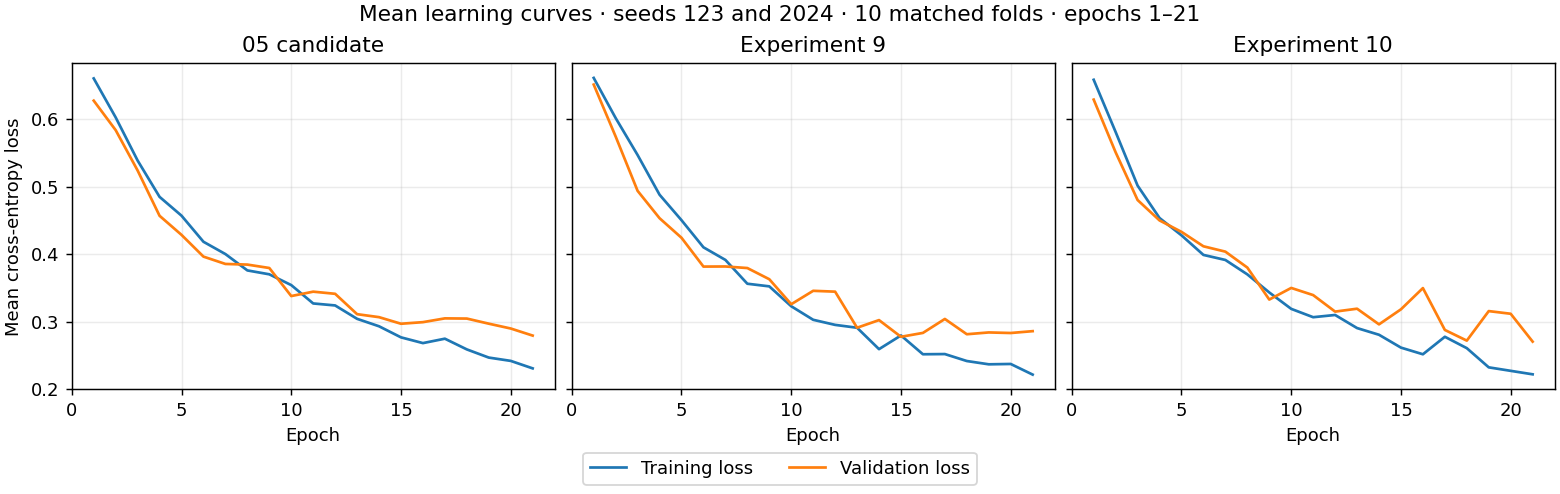

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Measured histories from the saved 05 and 06 runs, seeds 123 and 2024.
# Only the common observed range is included; no early-stopped run is extended.
_learning_curve_snapshot = {'05 candidate': {(123, 1): {'train_losses': [0.6580651191557559, 0.618046596611466, 0.5530936519614627, 0.48019870179571034, 0.4714175513593461, 0.42050147326031606, 0.4109160890824518, 0.36461624026948924, 0.3670311814532648, 0.33071790100166043, 0.3262042001438554, 0.35131472540222286, 0.29302743541850584, 0.2715634073211361, 0.27939752576435717, 0.24642952237734084, 0.26124716548369625, 0.2601128748544751, 0.25027926637161746, 0.22825600650337172, 0.2386272880869365], 'val_losses': [0.6118798638429969, 0.5691798301500695, 0.4958921051888822, 0.43590561722512605, 0.39869112672278445, 0.3932683287475641, 0.39282041068719786, 0.3766071387070501, 0.34113684719982573, 0.33197654109169666, 0.36631985119002874, 0.29748519382372823, 0.34416102570324925, 0.29453403827940283, 0.307396342941615, 0.30631652603874626, 0.267271318098652, 0.37965306853208214, 0.28256968986765246, 0.3033220652850617, 0.31449955963526743]}, (123, 2): {'train_losses': [0.657726875804684, 0.6096207774530977, 0.5130390984326345, 0.4821642156884899, 0.49280547761210963, 0.40788711308387693, 0.40457574301925564, 0.35926892894696927, 0.3560959212231542, 0.37370820804582566, 0.32177166868399015, 0.3249723865060442, 0.2871501863885465, 0.29029187906187953, 0.2996806169301852, 0.2647554114844217, 0.3594181202685958, 0.26386012427874683, 0.24199569926452724, 0.24410116816533328, 0.21289367361730277], 'val_losses': [0.6278008582807404, 0.5723546810239275, 0.7368080036553424, 0.4853262739644801, 0.43449729271349136, 0.392401556287837, 0.3815062252537716, 0.3834723570091052, 0.5169172624930461, 0.3377627961343369, 0.3468949397615334, 0.34733878545219377, 0.31279296337299023, 0.2909464090114178, 0.31508110050580573, 0.3134921493314822, 0.3222206155281743, 0.3037697787823103, 0.331996771596906, 0.2688291138800995, 0.28167774952908925]}, (123, 3): {'train_losses': [0.6532345899175316, 0.6080062538036962, 0.5469293100519842, 0.47673862512838255, 0.4080637695728014, 0.40439728750257126, 0.36647697354050607, 0.3519056893751571, 0.3350930818104688, 0.3055019591668576, 0.32309755387941747, 0.30809516948375587, 0.2535878264012043, 0.2494544131813436, 0.23950155538130066, 0.22364480219729135, 0.21607772079285523, 0.2337075668421232, 0.22670394545733139, 0.23182921451157132, 0.18910089277880832], 'val_losses': [0.6411315425534114, 0.63051641544449, 0.49436218771979074, 0.47860195462206073, 0.41866987330891264, 0.4047257179783141, 0.40135420872786337, 0.37273347767714027, 0.36712011889876606, 0.3410132172694459, 0.4961698259520011, 0.3463551218264571, 0.3286885266363435, 0.38158421278742616, 0.35327278565023545, 0.3229380964861481, 0.3534047540474532, 0.40462755896963437, 0.31142235136477747, 0.317706734034874, 0.3084552687276561]}, (123, 4): {'train_losses': [0.6548392953393242, 0.5598623055503039, 0.5079319929110289, 0.5337228765965252, 0.43628486281874956, 0.4108839189098017, 0.38723660542085964, 0.3956737823999216, 0.4587071607185532, 0.36644607400253054, 0.3388658208643331, 0.35214348691381336, 0.33291423572800816, 0.28685544536899793, 0.3150807932448963, 0.2860661677127691, 0.26689546761434707, 0.2858188164530036, 0.24619698683010444, 0.26706727418180376, 0.23624530585594505], 'val_losses': [0.6181140380485035, 0.6087240548891442, 0.5738530565645094, 0.42528944070279784, 0.45425665332149495, 0.36547965384625203, 0.37218324380500295, 0.535735492387096, 0.36167527380112174, 0.3173747403413707, 0.40846909745088616, 0.3207221441319056, 0.2959082167235862, 0.2963540988373701, 0.27728928517944806, 0.2646232718540895, 0.42942032314013007, 0.2567932833438722, 0.34739776798219324, 0.2635924662738992, 0.25763623158931964]}, (123, 5): {'train_losses': [0.6727800900319655, 0.6035310624173126, 0.5379035990928935, 0.4702517495162762, 0.46036923934366103, 0.38848121663863044, 0.39598238143222725, 0.3979226171598999, 0.36490845708089453, 0.3615200513062819, 0.33651022784806484, 0.3640439562598168, 0.3103039517209537, 0.3151589031345748, 0.27607517162587414, 0.2939577981876064, 0.2456890014000237, 0.2664386849165705, 0.24740021065388143, 0.24436312902289387, 0.2315254794623024], 'val_losses': [0.6050025045871734, 0.582734489440918, 0.43690299689769746, 0.4162944585084915, 0.3796579897403717, 0.4114797204732895, 0.34690660834312437, 0.3620032608509064, 0.4006753176450729, 0.3090633198618889, 0.2739932909607887, 0.3552203804254532, 0.30058651715517043, 0.2903830587863922, 0.27753220647573473, 0.24752197265625, 0.2503469601273537, 0.24606776982545853, 0.23750499486923218, 0.24530154913663865, 0.21139595210552214]}, (2024, 1): {'train_losses': [0.6670945051212563, 0.6076584949868783, 0.5336095892816247, 0.47465847611473766, 0.4472801894855425, 0.4599412213473792, 0.42335338587419, 0.39294919517945237, 0.3778940446657402, 0.4623706831610584, 0.36195308894546163, 0.33217545939625376, 0.3169536579426433, 0.33289645190640343, 0.28390384266270574, 0.31415891421440517, 0.2529941495313416, 0.26194138018244156, 0.2523415167398594, 0.2657493623096963, 0.23630068048149555], 'val_losses': [0.6288825028410582, 0.5326202623430071, 0.474072563174729, 0.41551896443661607, 0.41851211747160394, 0.36894487739890425, 0.3840651259724213, 0.3334862165828671, 0.35994643061146187, 0.354606970899515, 0.3010999981808618, 0.3670921013734019, 0.2628347613727213, 0.2799406447917487, 0.2648227109921577, 0.25782466808847526, 0.254277994692994, 0.23111548451182717, 0.24751892883868779, 0.2595158625980988, 0.2688560259304561]}, (2024, 2): {'train_losses': [0.6645890748417201, 0.597266768628698, 0.544000272314621, 0.46542349087824975, 0.42744524982508886, 0.44485059823036566, 0.39034859240287373, 0.34929578420898455, 0.3140900811362037, 0.33932324953592113, 0.30747021239944855, 0.3239365289871895, 0.27486706453659343, 0.3333327551884105, 0.25775618974296544, 0.25817917009186947, 0.23060459990289559, 0.23720621146876525, 0.2417598181605246, 0.2309388250275134, 0.2146664628597878], 'val_losses': [0.6119968415792114, 0.5554674021737226, 0.5250401348339806, 0.3971860268591349, 0.36767988589322453, 0.363952616061377, 0.3763645154850505, 0.3063972169690043, 0.303235979141476, 0.3358405669715917, 0.27413448591562817, 0.29382254408434544, 0.321768648643917, 0.29181319746737167, 0.29793531292718706, 0.28869228334256053, 0.25829698057334605, 0.2626725970810958, 0.24167927884644716, 0.294331623586562, 0.2527270588503042]}, (2024, 3): {'train_losses': [0.6627581722552388, 0.593803440000708, 0.5333194144285013, 0.4691818960922729, 0.514268530571916, 0.4203257215088081, 0.41782009740964754, 0.4022494466250889, 0.3725413292623179, 0.32117814197265254, 0.30402955565012163, 0.2940410670134023, 0.2980629359477215, 0.27439940839843274, 0.28649417622797396, 0.270564313220123, 0.2940017623029829, 0.26256711963369617, 0.2574053635865752, 0.230925872747729, 0.2651663276244213], 'val_losses': [0.6306497463927462, 0.5735970234202448, 0.4671360122451901, 0.5286121970025178, 0.4279155935453849, 0.4644730213646577, 0.43423102057982826, 0.359316574821591, 0.37897400692615923, 0.3447803492858031, 0.3182696224744446, 0.31272195692745697, 0.28703260663142455, 0.32215172163793976, 0.2795959299784212, 0.29784329695122264, 0.2819017039095501, 0.308100878263931, 0.2998033696988661, 0.26832770382132487, 0.25831630761006913]}, (2024, 4): {'train_losses': [0.6544513747223819, 0.6095201794467489, 0.5332605331927096, 0.4779187453880221, 0.4235232248960392, 0.4123160179387938, 0.3732393222773159, 0.35099720638985754, 0.32037063023120466, 0.32002882224080076, 0.2954483474412423, 0.24874486467015572, 0.2862300587990789, 0.26651285805348207, 0.22843919233335525, 0.23681913135937668, 0.2990824904231847, 0.22238605477450094, 0.21264396451372983, 0.21533887875168378, 0.21294324537877077], 'val_losses': [0.6454258811808078, 0.5759368945505018, 0.4772499172115623, 0.46837636094969753, 0.4848700186173864, 0.3521015268991298, 0.3407478295382681, 0.3515545428727646, 0.3612916317312888, 0.35316066847783384, 0.3106712384201656, 0.4303325448080758, 0.30956736086313597, 0.29937813642240385, 0.2995971084755158, 0.34591100232623445, 0.2986129243797231, 0.3229522094176937, 0.3166052244162634, 0.3752277907552749, 0.3418617146408818]}, (2024, 5): {'train_losses': [0.6619258729096885, 0.6215928169054405, 0.5858313717946085, 0.519439116538128, 0.4891230918908045, 0.41368502471305874, 0.4307122917561516, 0.39329921252259586, 0.43357694371838434, 0.35950305435887747, 0.3525793106756478, 0.3387530020835615, 0.3865832838685342, 0.30861750050125836, 0.29837595181673116, 0.28485831172666815, 0.3188387922539355, 0.2918442718893568, 0.28789794728206325, 0.2569392055180214, 0.26689341696809016], 'val_losses': [0.65655517578125, 0.6386657595634461, 0.559572634100914, 0.5177366554737091, 0.500758945941925, 0.4461539089679718, 0.42389816641807554, 0.4632850021123886, 0.4031750649213791, 0.3520083069801331, 0.34666492193937304, 0.33999266028404235, 0.3455006003379822, 0.3173342883586884, 0.2941083639860153, 0.34525620341300967, 0.33059722781181333, 0.3277742713689804, 0.35122716426849365, 0.29990956634283067, 0.2955654218792915]}}, 'Experiment 9': {(123, 1): {'train_losses': [0.6731265609095269, 0.6253580647525803, 0.5647860160351543, 0.5071150425441174, 0.4410868596027163, 0.4118829387663308, 0.3826764690880653, 0.33961388910086193, 0.3557316871796933, 0.3129988022479617, 0.30149641901905055, 0.30057783131012206, 0.2689760908577373, 0.23401687276242583, 0.27297671242607635, 0.21581193326231288, 0.2559078628500736, 0.2255433000629987, 0.3013745448490371, 0.24823124612669228, 0.22110725644996226], 'val_losses': [0.6744620989416247, 0.5809431948765788, 0.5006027868441146, 0.4148428097013326, 0.37700899901605467, 0.3584979237797104, 0.3129549408592632, 0.3961248814865999, 0.28197081855895734, 0.30076869795348415, 0.2543229422302818, 0.2553247645079533, 0.24870816718009403, 0.2441624646884537, 0.22732909844254037, 0.29301071974718684, 0.3421380857025299, 0.36073044694472695, 0.20893053204471077, 0.28977589659984704, 0.2860682112602894]}, (123, 2): {'train_losses': [0.6498389746282404, 0.5901736077255136, 0.5013166421201205, 0.46411116919476636, 0.4110942271103268, 0.3720201452727998, 0.3673663298807754, 0.33748582927677095, 0.3215541592911641, 0.3216965108389791, 0.29501889481130095, 0.28547244427822943, 0.25794248637726597, 0.2741976294402303, 0.28145653496635026, 0.25767003826721513, 0.24904815813734116, 0.22795462048527607, 0.2367178811833251, 0.2184377967010507, 0.21523068374311746], 'val_losses': [0.6333700485318621, 0.5247686639619625, 0.4493212848356845, 0.410130802742162, 0.40490390814085003, 0.33394025533091615, 0.3295121380861274, 0.36919742710130415, 0.31386512943277933, 0.3792351421147927, 0.29981977001668136, 0.3103225509116768, 0.3278224877432871, 0.2652465890056883, 0.308505289836836, 0.3099132961277325, 0.30115581077455167, 0.32286716909822355, 0.2559963769158472, 0.2825493899194344, 0.26888479345776956]}, (123, 3): {'train_losses': [0.6514082500828678, 0.5922611961351738, 0.5193790564152382, 0.45842484747722384, 0.4258380731914718, 0.3944112768604341, 0.36866915047122273, 0.29819208179148304, 0.3133416344946655, 0.31925035210577474, 0.2658302258070056, 0.2735621708961362, 0.30358351166603254, 0.23729874838262635, 0.3635423501208715, 0.22075813821141643, 0.3240074640486915, 0.21754541667867872, 0.1951510976834494, 0.22026132965868372, 0.19472206569337], 'val_losses': [0.6589617066294233, 0.5370525498627874, 0.4910523676055243, 0.47524561280402067, 0.4597063376524738, 0.4272026516659609, 0.40421838728809656, 0.37581111374673815, 0.5883496907942949, 0.33352702818926994, 0.3407393552339708, 0.31008336077969395, 0.31205236382573565, 0.4151034436864645, 0.37611285947564976, 0.2986303184448373, 0.3156099794809692, 0.2931712575233614, 0.3147535008433452, 0.289323334289117, 0.32704363303763845]}, (123, 4): {'train_losses': [0.6435863047675611, 0.5640746723694998, 0.49696918948033036, 0.45014859792875855, 0.4373744535938614, 0.4208958018876014, 0.39006547010209724, 0.3375000017676982, 0.3305742914032769, 0.32541278624850517, 0.289760738076963, 0.2915304999563347, 0.2796080153571937, 0.25898751830181294, 0.2782462902210322, 0.27906172903180587, 0.2501373674752465, 0.21814657964933132, 0.241589073843772, 0.2163857745408826, 0.21775148066220948], 'val_losses': [0.6277279284698569, 0.5223407157670672, 0.44478230036771926, 0.3911316688187026, 0.4306076579376173, 0.3477754704538164, 0.4197866595422739, 0.31945436663716753, 0.29378718444120105, 0.38034679254986975, 0.254060181246554, 0.30490734702051614, 0.29087571407206986, 0.28585070427206716, 0.25118316685424746, 0.28074446085382054, 0.25450620210346564, 0.24590646923494103, 0.2521272566677412, 0.23602181904448044, 0.32786387817696067]}, (123, 5): {'train_losses': [0.693385695371301, 0.6403478881651739, 0.5556918629604708, 0.49073378546772717, 0.4303859694167461, 0.39515610298611853, 0.3824541048840199, 0.3508624057532099, 0.33886887332732063, 0.3336348188025558, 0.27635853348421896, 0.29006608382935095, 0.26422426513050945, 0.26018318478192126, 0.25910539279845646, 0.24862265512579326, 0.2264791738207095, 0.3554296413686045, 0.23713590655000039, 0.2127101384219351, 0.2451643030916419], 'val_losses': [0.6578199148178101, 0.5856533259153366, 0.5159466117620468, 0.4494980305433273, 0.401764902472496, 0.32622013688087464, 0.3171775430440903, 0.33211199194192886, 0.49659821689128875, 0.28988561034202576, 0.4157988756895065, 0.2516978971660137, 0.26874593198299407, 0.3402135297656059, 0.2602753907442093, 0.2302926264703274, 0.42615898698568344, 0.22404002845287324, 0.22615386992692948, 0.25299152135849, 0.23671411573886872]}, (2024, 1): {'train_losses': [0.6545617018745732, 0.5629615660579708, 0.579783925369951, 0.4667159621012183, 0.4438365533634358, 0.4087111140403168, 0.43867034557989026, 0.35436973090712576, 0.3295041652438423, 0.30903125447471536, 0.3263666836525998, 0.2751089139367488, 0.2777462199341944, 0.24457081263000763, 0.2543928467103121, 0.2376686937218519, 0.23914020145580533, 0.22981996688228143, 0.21269375457488646, 0.3636767548172853, 0.22445289291214962], 'val_losses': [0.5934892592957458, 0.49565623679729265, 0.5054683215690217, 0.46859709756024637, 0.4016902127874017, 0.414976002642667, 0.3818205951530232, 0.3194172537583325, 0.30225059770268575, 0.3330360599307523, 0.4563588843538722, 0.27533700792959087, 0.29199068530990496, 0.26819210900777135, 0.29151572059598496, 0.2728390626818206, 0.23335644017417984, 0.23743880685409144, 0.5229695638020834, 0.2768044808975238, 0.2596578140934564]}, (2024, 2): {'train_losses': [0.6636722439541449, 0.5817522983809328, 0.5392978376043279, 0.46689136555114946, 0.5452506837673886, 0.4671122162999906, 0.425822125685373, 0.4079641612799764, 0.3950408112928446, 0.35660168405445125, 0.37735545042095037, 0.2987523849179572, 0.2542596130936014, 0.2516387088031204, 0.2704091470917964, 0.2803760066523927, 0.23421090186246188, 0.24325857545515567, 0.23316697711821874, 0.23223219615815965, 0.205123759800349], 'val_losses': [0.6067952211957854, 0.6863832400641708, 0.44006010871438594, 0.4462877428420236, 0.4456346318172146, 0.36994051042004167, 0.4036484269709602, 0.4193415673350991, 0.3239963656970274, 0.3615696546026851, 0.31207989160017896, 0.2781024783635019, 0.28225773100587437, 0.3647781267814408, 0.2723265392780144, 0.3120602992329909, 0.34520978246731365, 0.2714378651111123, 0.2743636366462979, 0.28949869795037997, 0.2970658358680115]}, (2024, 3): {'train_losses': [0.6870135707680546, 0.6634722963172945, 0.6379603597212842, 0.6029666406236769, 0.5158272536350987, 0.4600797620306513, 0.4358372214429562, 0.4160459327265774, 0.38967792390151035, 0.3428019150476017, 0.320898156857012, 0.3487769576981489, 0.2978004189970339, 0.2809624782271991, 0.28139070048057185, 0.28851414042715906, 0.24705637034989852, 0.2381605028275717, 0.24255515366722993, 0.23791013263160143, 0.21906377168391147], 'val_losses': [0.6795772426410628, 0.652244060396034, 0.5835352114799238, 0.5503908507177763, 0.4783183611070627, 0.4186967197236985, 0.4022310994495855, 0.43526099366933757, 0.3619904811508559, 0.3165584655937005, 0.3726843060734116, 0.38027017658744644, 0.2760434111702108, 0.3011275528004608, 0.25694184037755213, 0.2872825974244566, 0.25959403808243176, 0.24737005163204634, 0.27959365933855, 0.2643003287345078, 0.3229253603104862]}, (2024, 4): {'train_losses': [0.6465571054423682, 0.5793630786454965, 0.517410836806078, 0.4865555342458136, 0.4212822240958061, 0.3800914639713052, 0.36318241765930237, 0.353606222991542, 0.3130895509729372, 0.29295470095758597, 0.2911171160452503, 0.2716915474954879, 0.23067173235182267, 0.23348230445091137, 0.24339829629181142, 0.2421559228889197, 0.23865192698856302, 0.20876819710664607, 0.22873480973397953, 0.206383299162366, 0.19386155145215225], 'val_losses': [0.655055966332694, 0.5391485980737989, 0.46645560795644364, 0.4467840157565298, 0.38754447784007895, 0.3792054237235001, 0.3542430589317904, 0.3742786519623991, 0.29946401817404966, 0.2695333302206711, 0.2777693589157033, 0.2574238819868022, 0.2888807318292303, 0.26342625447151446, 0.25619611450444874, 0.2894260336491178, 0.28026367505762806, 0.33732366366921185, 0.2676470170139895, 0.2836111009677994, 0.28830477808866173]}, (2024, 5): {'train_losses': [0.6517941931326441, 0.619456321836632, 0.5579373541279374, 0.4879474851572625, 0.43150584849984475, 0.39073209218518384, 0.3591514097010235, 0.36493732086223235, 0.43409889899310294, 0.31193378484137707, 0.28118229942901113, 0.3143837910574916, 0.47257135404604617, 0.3144272385727951, 0.28820159214307955, 0.24333346248212678, 0.25211111472403147, 0.24883674068892855, 0.23556233269403284, 0.2135559273100345, 0.2754027265533109], 'val_losses': [0.7285358905792236, 0.6207712113857269, 0.5415596634149551, 0.48008154034614564, 0.4554149448871613, 0.4385196179151535, 0.49093714356422424, 0.45235691368579867, 0.3651915848255157, 0.2920179784297943, 0.47182149440050125, 0.8194702059030533, 0.3201740697026253, 0.2726730272173882, 0.27260695248842237, 0.256490096449852, 0.27975106090307233, 0.2707932904362679, 0.23518286496400834, 0.3643700011074543, 0.24213598817586898]}}, 'Experiment 10': {(123, 1): {'train_losses': [0.670568553851344, 0.6066005031345231, 0.5129485428333282, 0.4452476758837979, 0.4172167547442025, 0.3846835986488235, 0.40216091664875286, 0.3721288027777536, 0.32421070548675995, 0.3486635554886756, 0.32754379954546203, 0.29357000812742967, 0.29294388575605695, 0.24365822407573068, 0.27579915396933063, 0.2604448164171076, 0.2435558882069397, 0.2387924551359862, 0.2596267863864185, 0.24094054805563467, 0.23561540682707927], 'val_losses': [0.6541820536149996, 0.6125485964374751, 0.4209681358420496, 0.45251737783860263, 0.3801063796152822, 0.354068066425784, 0.36534494387908517, 0.4374373138434692, 0.3062588065584129, 0.3006621151698341, 0.29435831738920226, 0.3520202853057223, 0.3174970377934009, 0.31847836601771295, 0.2891492012690904, 0.3974992820163108, 0.2845264475773063, 0.2756888927268793, 0.4889493894725542, 0.35615182331293854, 0.273610822212334]}, (123, 2): {'train_losses': [0.6555405529048977, 0.5792529465672752, 0.49184042707794084, 0.4517329413957737, 0.40223590865882225, 0.3812398842186758, 0.3725279236759697, 0.35420773232345554, 0.3473189040635214, 0.2980240276801986, 0.2942520805103929, 0.32367040947462933, 0.28568152034552136, 0.2642320609395265, 0.24064724213521368, 0.25167332466514614, 0.2451754401344298, 0.2340248508766491, 0.23612667820528904, 0.22172820113202962, 0.19420360592908908], 'val_losses': [0.619933042292283, 0.6317487999022942, 0.45728644970195176, 0.5685306152450151, 0.479500250281508, 0.47993031134819975, 0.3567600331829159, 0.3684070108752521, 0.30913795854873094, 0.3607035488877099, 0.2799221142238685, 0.29078510210695574, 0.29582815934933204, 0.2924907467146861, 0.2849767778933373, 0.26617888582477234, 0.25273894082255827, 0.2464141112708195, 0.26085170177010075, 0.24767055875413618, 0.27159577811318536]}, (123, 3): {'train_losses': [0.6467354771037261, 0.5677038419321006, 0.4722059102887208, 0.46990804431128114, 0.42661718894972156, 0.3691241102161021, 0.36353435101958803, 0.3778926236315435, 0.3315223390853507, 0.3182865502726539, 0.30962530781376296, 0.2925239111981351, 0.28200573392287887, 0.2913057901203307, 0.2671534669928874, 0.23928039650569233, 0.21880656481950617, 0.20775174462785967, 0.28620836340814293, 0.21787710091213836, 0.20834928079684636], 'val_losses': [0.6131241640940633, 0.5225120485757371, 0.4664649138940829, 0.4539548266342496, 0.41711045889839576, 0.45535209626423606, 0.5456790745815384, 0.4173491194240772, 0.3796746715949703, 0.3700030210233552, 0.39909057453785357, 0.41624007603832497, 0.36796248683305544, 0.33138768472404123, 0.35319815729266013, 0.3168709798022594, 0.3099812588587728, 0.31797242016064414, 0.3237300182800055, 0.3518639182747339, 0.30886277932429984]}, (123, 4): {'train_losses': [0.6622371509589912, 0.6122209685720323, 0.5439494710970185, 0.4763487032959448, 0.46620793862446896, 0.43695397505178085, 0.3705576972764447, 0.4122092449051834, 0.3381576451849677, 0.3114101963403721, 0.3063582071188085, 0.27780794084583144, 0.3139704870624832, 0.25473212073858326, 0.24173190484777243, 0.24886269243731687, 0.23573162266730519, 0.4172105765142946, 0.21801414215880638, 0.1963318238733155, 0.20213954897476932], 'val_losses': [0.6957279085370239, 0.5714429308692243, 0.5114080998756433, 0.4709152118810612, 0.5695675336683279, 0.3556937943691405, 0.347777932360072, 0.39269652716653, 0.3149300854003225, 0.3185071662021946, 0.3593703410892843, 0.2517086255575916, 0.25589870184520697, 0.2576492334639137, 0.24916169360824758, 0.2719538119535261, 0.339488230007367, 0.24152478056951104, 0.26674997490595714, 0.2762895944630553, 0.24659254887802062]}, (123, 5): {'train_losses': [0.6708748823385744, 0.6010618001872505, 0.5016729891114518, 0.4684457875486475, 0.4297749496694666, 0.39391057179352945, 0.4226656648971581, 0.38688664579317206, 0.3618446070457173, 0.3361342531684032, 0.3560161229884513, 0.29875630595230984, 0.2913110861525729, 0.42243187575139735, 0.3103371063868205, 0.2589350480621106, 0.2573259499539096, 0.23329867229933307, 0.23294306841513543, 0.21488399260512023, 0.2450638850715673], 'val_losses': [0.5997520565986634, 0.5144482046365738, 0.45154469907283784, 0.4418774783611298, 0.35778314173221587, 0.4348254859447479, 0.40614829063415525, 0.3335674077272415, 0.37389746606349944, 0.485996875166893, 0.31981213092803956, 0.3116895630955696, 0.3066744193434715, 0.33542390912771225, 0.29955083578825, 0.25164787769317626, 0.27066459506750107, 0.23968486934900285, 0.2402534618973732, 0.23499396741390227, 0.253048287332058]}, (2024, 1): {'train_losses': [0.6527204426210185, 0.5880726113137285, 0.5076591961103217, 0.44715415070229736, 0.45225793388051533, 0.4469278999143342, 0.39590214428637793, 0.4092214386256895, 0.3568501351103593, 0.3341545509065582, 0.3089702260838016, 0.3426810493017674, 0.29719304304427685, 0.2600384260515449, 0.2695037109380993, 0.25447122742213596, 0.24911462986552893, 0.2710171652695023, 0.22782252797463493, 0.2520506951554344, 0.20124173640554432], 'val_losses': [0.5994610327797887, 0.5143455488032826, 0.45352114286524003, 0.4098698535811102, 0.4950092159606215, 0.3791212682830564, 0.4489483135140188, 0.3310123823129036, 0.31708782037494415, 0.32636920187426105, 0.35906300947325437, 0.29968909047452613, 0.2964596518103508, 0.2895158035361506, 0.2810825354583437, 0.3128543939917258, 0.2522739769885045, 0.2501870404894075, 0.30920236690022124, 0.33275772218020905, 0.26661356401591974]}, (2024, 2): {'train_losses': [0.6577480604475769, 0.5407795303981004, 0.4890582027546742, 0.4474980144043593, 0.42365917414775234, 0.40861549232494804, 0.37362350037993625, 0.32866506544772944, 0.30233293388471505, 0.33037451676159096, 0.2821230608694087, 0.45978129949545543, 0.2913048453019266, 0.26905727602500795, 0.2568984050608573, 0.2586695028596724, 0.24108713065199291, 0.2935550961460532, 0.21461849414619355, 0.21927420150369567, 0.2414355485011197], 'val_losses': [0.5958392644225623, 0.5686442645910744, 0.4949450684113666, 0.3927809840468603, 0.434422240424263, 0.457744696331312, 0.3435265466199486, 0.330234580165547, 0.3059568870000286, 0.30094792776250767, 0.4650388429959731, 0.30529955284803456, 0.3333930188871201, 0.2850028292603814, 0.2647979938776183, 0.2812598098963035, 0.27737981662704725, 0.2743978905593077, 0.35828751973457656, 0.42669783684954454, 0.2555701181711774]}, (2024, 3): {'train_losses': [0.6575651359762518, 0.5460117560109401, 0.46989473602672804, 0.41616189155643424, 0.4256019536536463, 0.3680102277898454, 0.41225750522509463, 0.32657988159245843, 0.34239392490100784, 0.286278682034274, 0.265131088667669, 0.24823098668621002, 0.31526295278317185, 0.26642971149038175, 0.22823573306307418, 0.23338264312859355, 0.2709678034330787, 0.18924807721715556, 0.21788764566799013, 0.2443034928567876, 0.26158959530613335], 'val_losses': [0.6250581635492984, 0.47577570754790977, 0.5737715862993139, 0.3900029174635343, 0.39966461888726257, 0.4272450470478735, 0.3743122706532107, 0.35387182597802064, 0.35855948767186696, 0.4025811004768651, 0.27589672729605086, 0.2966789013685838, 0.41900961676676324, 0.2746784492073772, 0.2866814960943204, 0.3281235030831949, 0.2743974438058996, 0.31120300274400325, 0.2811021602413736, 0.3116033754987509, 0.27510207798622105]}, (2024, 4): {'train_losses': [0.6730811244235406, 0.6136751547978432, 0.5577509850495882, 0.469154168759485, 0.4154562439104587, 0.4241226827108758, 0.3733790220688398, 0.3697128993453965, 0.35481404116491927, 0.31142884855240655, 0.30430709195504035, 0.2866798223040574, 0.26786352833987026, 0.26840863927954917, 0.25716944332710023, 0.2535699210126049, 0.4703217073171657, 0.24522468679971465, 0.21594252197517608, 0.22303324214829567, 0.21808255438867807], 'val_losses': [0.661392835813148, 0.5802148424576377, 0.4799070243152131, 0.42572245271035075, 0.40776291489601135, 0.3978293725634661, 0.4793035758432941, 0.3566569290428518, 0.31044170947461114, 0.3397209467917588, 0.3528890351640101, 0.33552903085482827, 0.27716111338398536, 0.3131035462810986, 0.4379013067465334, 0.36694625447100937, 0.29159619977169693, 0.26470188578341236, 0.2871772726284009, 0.3399041298997365, 0.2892819761858551]}, (2024, 5): {'train_losses': [0.6402541826075854, 0.5565728658456297, 0.46973425335601854, 0.44407917517367923, 0.41984223897026335, 0.37459375999426914, 0.42664378974296596, 0.36176796027711616, 0.3716124638775799, 0.3126093690454774, 0.30943359295341455, 0.27315958879447055, 0.26496105292968664, 0.2628233674623513, 0.2648505855386502, 0.25433996514739277, 0.34117558533528886, 0.27423499835614473, 0.21036801607902175, 0.2374223566547361, 0.20841846436354972], 'val_losses': [0.6285124003887177, 0.5187394827604294, 0.4930947721004486, 0.49388805627822874, 0.3893332898616791, 0.3742861807346344, 0.368881544470787, 0.479215145111084, 0.349434070289135, 0.2926225081086159, 0.28643866181373595, 0.287279948592186, 0.3199575960636139, 0.25982367545366286, 0.434292870759964, 0.7024731054902077, 0.32170320600271224, 0.2942993491888046, 0.338132506608963, 0.23692527264356614, 0.26111030504107474]}}}
matched_folds = [(seed, fold) for seed in (123, 2024) for fold in range(1, 6)]
common_epochs = min(len(history[key]["train_losses"])
                    for history in _learning_curve_snapshot.values() for key in matched_folds)
epochs = np.arange(1, common_epochs + 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True, constrained_layout=True)
for ax, (title, histories) in zip(axes, _learning_curve_snapshot.items()):
    training = np.array([histories[key]["train_losses"][:common_epochs] for key in matched_folds])
    validation = np.array([histories[key]["val_losses"][:common_epochs] for key in matched_folds])
    ax.plot(epochs, training.mean(axis=0), label="Training loss", color="tab:blue")
    ax.plot(epochs, validation.mean(axis=0), label="Validation loss", color="tab:orange")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Mean cross-entropy loss")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2)
fig.suptitle(f"Mean learning curves · seeds 123 and 2024 · 10 matched folds · epochs 1–{common_epochs}")
plt.show()


## Observed GPU results

| Split seed | 05 candidate loss | Experiment 9 loss | Experiment 10 loss | 05 accuracy | Experiment 9 accuracy | Experiment 10 accuracy |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 42 | 0.2456 | 0.2286 | 0.2504 | 89.96% | 91.02% | 89.34% |
| 123 | 0.2526 | 0.2416 | 0.2453 | 89.28% | 89.96% | 89.84% |
| 2024 | 0.2556 | 0.2436 | 0.2496 | 89.03% | 89.21% | 89.78% |

The original 05 candidate has 355,410 parameters; experiments 9 and 10 have 392,338 and 228,562 respectively. Experiment 9 has the lowest mean log loss in all three splits in this run. Experiment 10 improves on the saved reference for seeds 123 and 2024 but is slightly worse for seed 42. The fourth pooling in experiment 10 also changes classifier size, so the result represents a combined architecture change.

The 05 candidate was selected using seed 42, the same validation folds select epochs and support the comparison, and folds/splits share data. These results do not establish an independent final score. A different training seed, repeated nested CV, or an untouched test set would strengthen the assessment. Training curves use augmentation and dropout; validation curves use evaluation mode.
